# Data Science Model 2: Product/Category Demand Prediction

**Academic subject mapping:** Data Science, time-series feature engineering.

**Objective:** forecast next-day visitor-interaction volume per product category, to surface
in the admin analytics dashboard (Part 8).

**⚠️ DATA LABEL — READ BEFORE INTERPRETING ANYTHING BELOW:** the MallMind platform's real
`search_events`/`product_interactions` tables currently hold only a handful of rows (manual
API testing during development) — nowhere near enough history to model. The series used here
is **deterministically SIMULATED** (`../data/generate_demand_series.py`, fixed random seed) with
an explicit base level + linear trend + weekend seasonality + noise per category. Every number
in this notebook describes a synthetic signal's predictability, **not real consumer demand**
(Part 17 rule #7). Swapping in the real `search_events` aggregation once enough history exists
is a drop-in replacement for the one `pd.read_csv` call below.


In [1]:
import sys
sys.path.insert(0, '../app')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 20)


## 1. Data collection & dictionary

In [2]:
raw = pd.read_csv('../data/demand_series.csv')
print(raw.shape)
raw.head()


(3840, 3)


,date,category,search_count
0,2026-01-01,Apparel,42
1,2026-01-02,Apparel,34
2,2026-01-03,Apparel,61
3,2026-01-04,Apparel,62
4,2026-01-05,Apparel,28


In [3]:
dictionary = pd.DataFrame({
    'column': raw.columns,
    'description': [
        'Calendar date (one row per category per day)',
        'Product category (16 categories, matching the seeded catalogue)',
        'SIMULATED count of search/view interactions for that category that day',
    ],
})
dictionary


,column,description
0,date,Calendar date (one row per category per day)
1,category,"Product category (16 categories, matching the ..."
2,search_count,SIMULATED count of search/view interactions fo...


## 2. Data cleaning

In [4]:
print('Missing values:')
print(raw.isna().sum())
print()
print('Duplicate (date, category) rows:', raw.duplicated(subset=['date','category']).sum())
print('Negative counts:', (raw['search_count'] < 0).sum())
print('Date range:', raw['date'].min(), 'to', raw['date'].max())
print('Categories:', raw['category'].nunique())


Missing values:
date            0
category        0
search_count    0
dtype: int64

Duplicate (date, category) rows: 0
Negative counts: 0
Date range: 2026-01-01 to 2026-08-28
Categories: 16


## 3. Exploratory Data Analysis

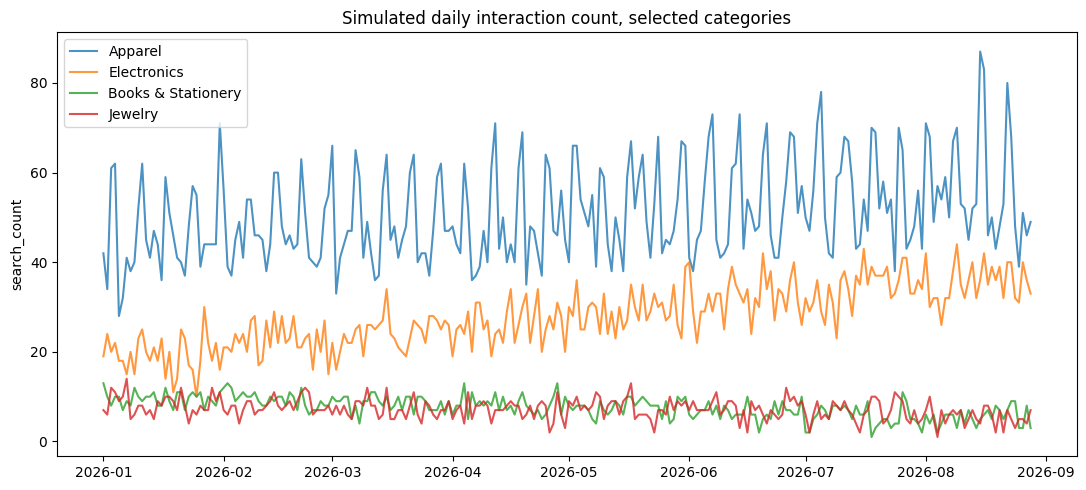

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
for category in ['Apparel', 'Electronics', 'Books & Stationery', 'Jewelry']:
    series = raw[raw['category'] == category].sort_values('date')
    ax.plot(pd.to_datetime(series['date']), series['search_count'], label=category, alpha=0.8)
ax.legend()
ax.set_title('Simulated daily interaction count, selected categories')
ax.set_ylabel('search_count')
plt.tight_layout()
plt.savefig('demand_series_sample.png', dpi=100)
plt.show()


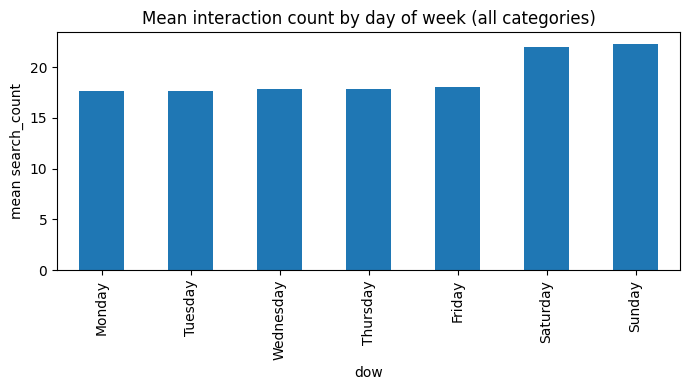

In [6]:
raw['date'] = pd.to_datetime(raw['date'])
raw['dow'] = raw['date'].dt.day_name()
weekday_means = raw.groupby('dow')['search_count'].mean().reindex(
    ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
weekday_means.plot(kind='bar', figsize=(7,4), title='Mean interaction count by day of week (all categories)')
plt.ylabel('mean search_count')
plt.tight_layout()
plt.savefig('demand_weekday_seasonality.png', dpi=100)
plt.show()


## 4. Feature engineering

Per (category, day) row: `lag_1` (yesterday), `lag_7` (same weekday last week), `rolling_mean_7`
(trailing 7-day mean — this doubles as the baseline forecast), `day_of_week`, `is_weekend`,
`day_index` (captures trend), and one-hot `category`. See `../app/demand_prediction.py`.


In [7]:
from demand_prediction import engineer_features, time_based_split, build_model_matrix

featured = engineer_features(raw.drop(columns=['dow']))
featured.head()


,date,category,search_count,lag_1,lag_7,rolling_mean_7,day_of_week,is_weekend,day_index
0,2026-01-08,Apparel,38,41.0,42.0,42.857143,3,0,7
1,2026-01-09,Apparel,40,38.0,34.0,42.285714,4,0,8
2,2026-01-10,Apparel,52,40.0,61.0,43.142857,5,1,9
3,2026-01-11,Apparel,62,52.0,62.0,41.857143,6,1,10
4,2026-01-12,Apparel,45,62.0,28.0,41.857143,0,0,11


## 5. Train/test split — TIME-BASED, per category

A random shuffle split would leak future days into training. Instead, for every category,
the **last 20% of its days (chronologically)** are held out as test; the model never sees
a test-period date during training.


In [8]:
train_df, test_df = time_based_split(featured, test_fraction=0.2)
print('train rows:', len(train_df), ' test rows:', len(test_df))
print('train date range:', train_df['date'].min(), '-', train_df['date'].max())
print('test date range: ', test_df['date'].min(), '-', test_df['date'].max())


train rows: 2976  test rows: 752
train date range: 2026-01-08 00:00:00 - 2026-07-12 00:00:00
test date range:  2026-07-13 00:00:00 - 2026-08-28 00:00:00


## 6. Model training: Random Forest vs. moving-average baseline

In [9]:
from demand_prediction import train_random_forest, baseline_predict, mae, rmse

X_train, y_train, category_columns = build_model_matrix(train_df)
X_test, y_test, _ = build_model_matrix(test_df, category_columns=category_columns)

model = train_random_forest(X_train, y_train)
rf_preds = model.predict(X_test)
baseline_preds = baseline_predict(test_df)

print('Random Forest   -> MAE:', round(mae(y_test, rf_preds), 3), ' RMSE:', round(rmse(y_test, rf_preds), 3))
print('Moving avg (7d) -> MAE:', round(mae(y_test, baseline_preds), 3), ' RMSE:', round(rmse(y_test, baseline_preds), 3))


Random Forest   -> MAE: 2.905  RMSE: 3.937
Moving avg (7d) -> MAE: 3.524  RMSE: 4.921


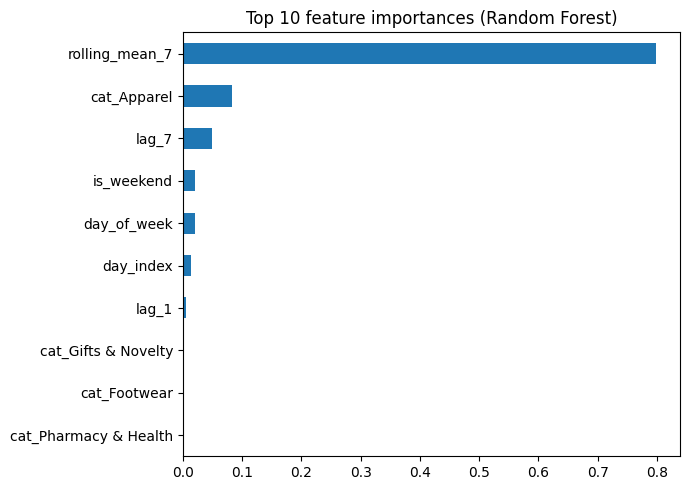

In [10]:
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importances.head(10).plot(kind='barh', figsize=(7,5), title='Top 10 feature importances (Random Forest)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('demand_feature_importance.png', dpi=100)
plt.show()


## 7. Evaluation chart: predicted vs actual (one category)

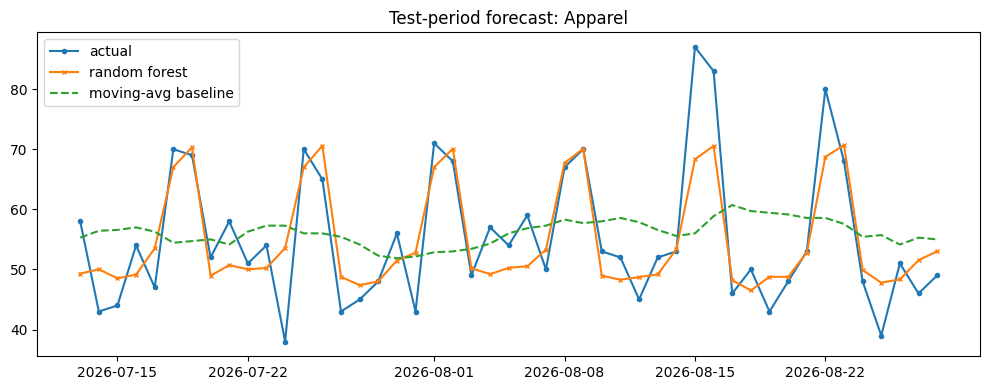

In [11]:
sample_category = 'Apparel'
mask = test_df['category'] == sample_category
sample_test = test_df[mask].sort_values('date')
sample_idx = test_df.index[mask]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sample_test['date'], y_test[mask.values], label='actual', marker='o', markersize=3)
ax.plot(sample_test['date'], rf_preds[mask.values], label='random forest', marker='x', markersize=3)
ax.plot(sample_test['date'], baseline_preds[mask.values], label='moving-avg baseline', linestyle='--')
ax.legend()
ax.set_title(f'Test-period forecast: {sample_category}')
plt.tight_layout()
plt.savefig('demand_forecast_example.png', dpi=100)
plt.show()


## 8. Interpretation & limitations

The Random Forest model beats the moving-average baseline on both MAE and RMSE on held-out
(chronologically later) data, by making use of the weekly seasonality, per-category trend
(`day_index`), and category identity in addition to the recent-average signal the baseline
relies on alone. `rolling_mean_7` dominates feature importance, as expected — the model is
fundamentally "the recent average, adjusted for day-of-week and category-specific trend."

**Limitations (stated honestly, per Part 17 rule #18):**
- This entire notebook models a SIMULATED series. No claim is made about real visitor demand.
- 240 days of synthetic history per category is enough to demonstrate the modelling approach,
  not enough to validate it against genuine seasonal effects (e.g. real festival/sale spikes).
- The simulation's trend/seasonality parameters were chosen by the developer, not fit from any
  real retail dataset — a production version must replace `generate_demand_series.py` with a
  real aggregation over `search_events`/`product_interactions` once sufficient history exists.
